## AI model detecting gravitational wave signals from black hole collisions
### Mateusz Marcol


In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal
from pycaret.classification import setup
from pycaret.classification import optimize_threshold
from pycaret.classification import predict_model
import re
from pycaret.classification import compare_models
from pycaret.classification import create_model, tune_model 
from pycaret.classification import finalize_model, save_model

## 1. Initial LIGO data analysis and prototype AI model

In [34]:
DATA = "H-H1_LOSC_4_V2-1126259446-32.txt.gz"

In [35]:
df = pd.read_csv(DATA, compression='gzip', comment='#', names=['Odksztalcenie'])

In [36]:
df

,Odksztalcenie
0,2.177040e-19
1,2.087639e-19
2,2.396812e-19
3,2.286722e-19
4,2.132240e-19
...,...
131067,8.399919e-20
131068,4.972658e-20
131069,3.553655e-20
131070,6.335335e-20


In [37]:
df.head(5)

,Odksztalcenie
0,2.177040e-19
1,2.087639e-19
2,2.396812e-19
3,2.286722e-19
4,2.132240e-19


In [38]:
df.index=df.index + 1

In [39]:
df.head(5)

,Odksztalcenie
1,2.177040e-19
2,2.087639e-19
3,2.396812e-19
4,2.286722e-19
5,2.132240e-19


In [40]:
df.sample(10)

,Odksztalcenie
68792,-3.964989e-20
32611,-8.977887e-20
89430,9.991194e-20
122507,-1.479799e-20
26553,-1.189601e-19
93707,-8.836379e-20
18841,-1.860519e-19
101355,-7.661317e-20
4217,1.213537e-20
77703,-5.026792e-19


In [41]:
df.describe()

,Odksztalcenie
count,1.310720e+05
mean,5.895523e-23
std,2.201824e-19
min,-7.044666e-19
25%,-1.410278e-19
50%,-1.555217e-21
75%,1.394112e-19
max,7.706262e-19


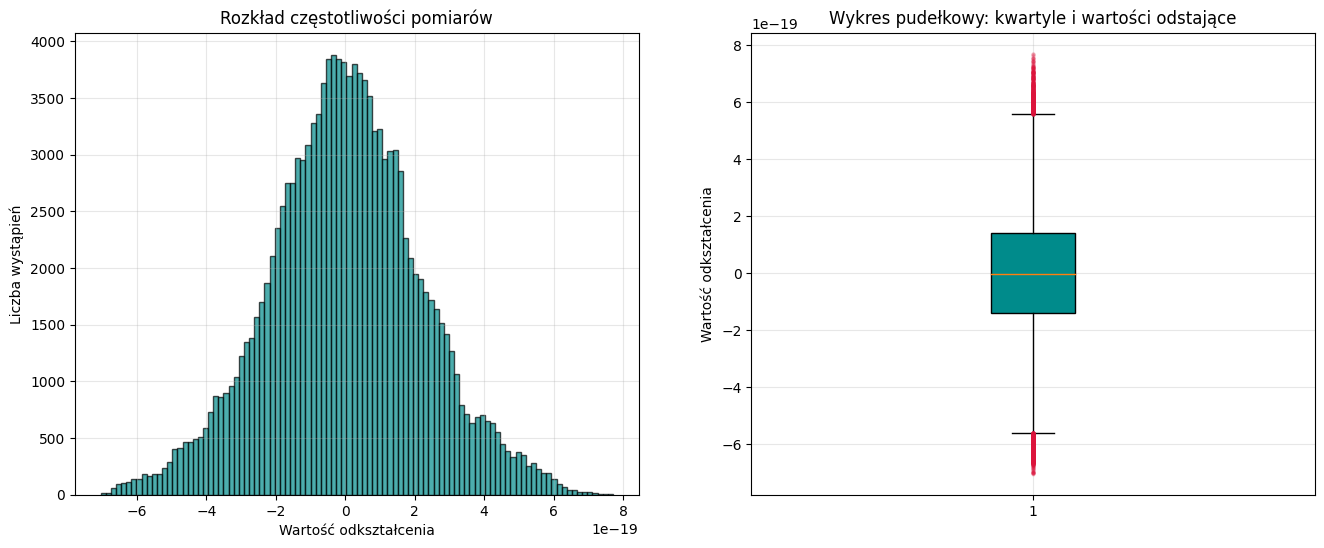

In [42]:
fig, (hist, box) = plt.subplots(1, 2, figsize=(16,6))

hist.hist(df['Odksztalcenie'], bins = 100, color = 'darkcyan', edgecolor='black', alpha=0.7)
hist.set_title('Rozkład częstotliwości pomiarów')
hist.set_xlabel("Wartość odkształcenia")
hist.set_ylabel("Liczba wystąpień")
hist.grid(True, alpha=0.3)

box.boxplot(df['Odksztalcenie'], patch_artist=True, 
            boxprops=dict(facecolor='darkcyan', edgecolor='black'),
            flierprops=dict(
                marker='o',
                markerfacecolor='crimson',
                markeredgecolor='none',
                markersize=3.0,
                alpha=0.2,
                linestyle='none'           )

            )
box.set_title("Wykres pudełkowy: kwartyle i wartości odstające")
box.set_ylabel("Wartość odkształcenia")
box.grid(True, alpha=0.3)

plt.show()

In [43]:
df.dtypes

Odksztalcenie    float64
dtype: object

In [44]:
df.duplicated().sum()

0

In [45]:
df.isnull().sum()

Odksztalcenie    0
dtype: int64

In [46]:
df['Czas'] = np.linspace(0,32,len(df))

In [47]:
df.head(5)

,Odksztalcenie,Czas
1,2.177040e-19,0.000000
2,2.087639e-19,0.000244
3,2.396812e-19,0.000488
4,2.286722e-19,0.000732
5,2.132240e-19,0.000977


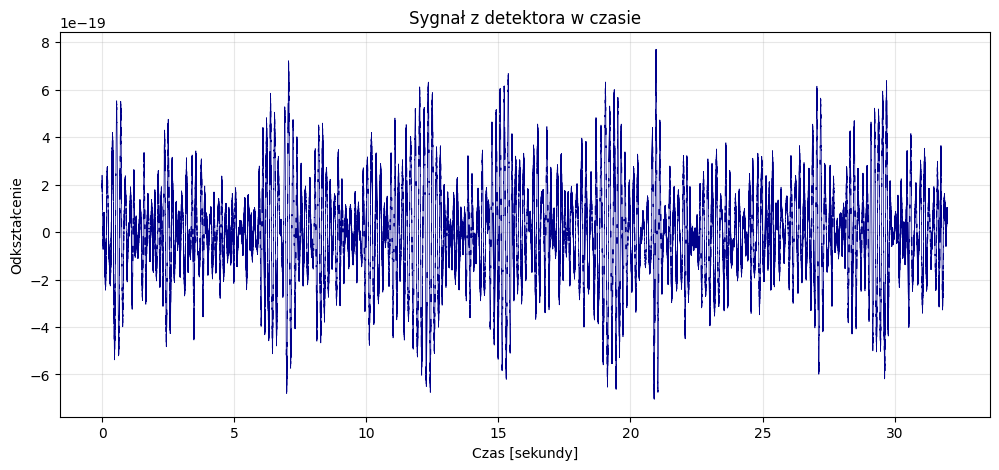

In [48]:
plt.figure(figsize=(12,5))
plt.plot(df['Czas'], df['Odksztalcenie'], color='darkblue', linewidth=0.5)
plt.title("Sygnał z detektora w czasie")
plt.xlabel("Czas [sekundy]")
plt.ylabel("Odkształcenie")
plt.grid(True, alpha=0.3)
plt.show()

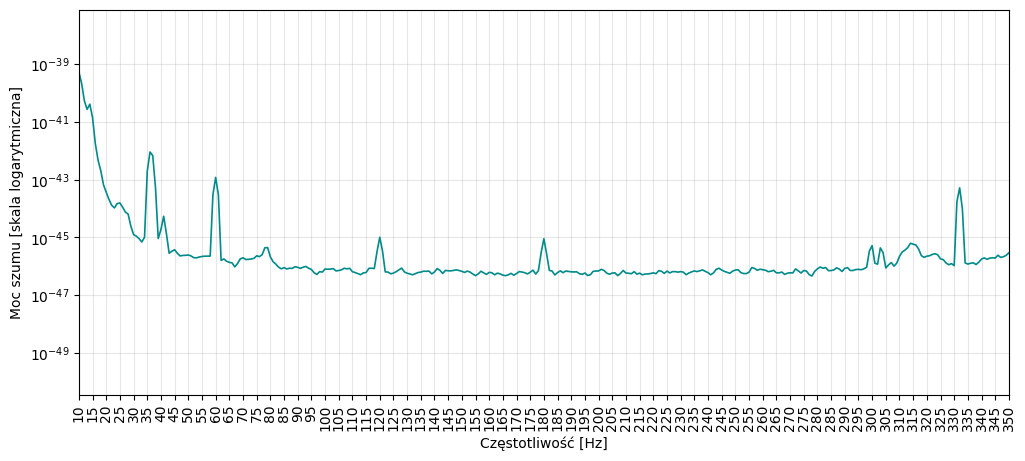

In [49]:
f, p = signal.welch(df['Odksztalcenie'].values, fs=4096.0, nperseg=4096)

plt.figure(figsize=(12,5))
plt.semilogy(f, p, color='darkcyan', linewidth=1.2, label = "Surowy sygnał")
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Moc szumu [skala logarytmiczna]")
plt.xticks(np.arange(10,360,5), rotation=90)
plt.xlim(10,350)
plt.grid(True, alpha=0.3)
plt.show()

In [50]:
b_notch60, a_notch60 = signal.iirnotch(60.0, Q=30.0, fs=4096.0)
df["Odksztalcenie"] = signal.filtfilt(b_notch60, a_notch60, df['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(300.0, Q=30.0, fs=4096.0)
df['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(36.0, Q=30.0, fs=4096.0)
df['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(332.0, Q=30.0, fs=4096.0)
df['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(120.0, Q=30.0, fs=4096.0)
df['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(180.0, Q=30.0, fs=4096.0)
df['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df['Odksztalcenie'])




In [51]:
df['Oczyszczone'] = signal.detrend(df['Odksztalcenie'])
df.head(5)

,Odksztalcenie,Czas,Oczyszczone
1,2.176792e-19,0.000000,2.215796e-19
2,2.082462e-19,0.000244,2.121466e-19
3,2.388437e-19,0.000488,2.427440e-19
4,2.277298e-19,0.000732,2.316300e-19
5,2.123756e-19,0.000977,2.162757e-19


In [52]:
from scipy import fft

sygnal_fft = fft.rfft(df['Oczyszczone'].values)

profil_szumu = np.abs(sygnal_fft)
profil_szumu_wygładzony = signal.medfilt(profil_szumu, kernel_size=501)

sygnal_fft_wybielony = sygnal_fft / (profil_szumu_wygładzony + 1e-25)

df['Oczyszczone'] = fft.irfft(sygnal_fft_wybielony, n=len(df))


In [53]:
tukey_window = signal.windows.tukey(len(df), alpha=0.1)
df['Oczyszczone_tukey'] = df["Oczyszczone"] * tukey_window
df.head(5)

,Odksztalcenie,Czas,Oczyszczone,Oczyszczone_tukey
1,2.176792e-19,0.000000,0.340508,0.000000e+00
2,2.082462e-19,0.000244,0.168591,9.685496e-09
3,2.388437e-19,0.000488,0.301938,6.938477e-08
4,2.277298e-19,0.000732,0.015245,7.882144e-09
5,2.123756e-19,0.000977,0.109186,1.003625e-07


In [54]:
f_low = 35.0
f_high = 350.0

nyquist = 0.5 * 4096

low = f_low/nyquist
high = f_high/nyquist
b, a = signal.butter(4, [low, high], btype='band')
df["Przefiltrowane"] = signal.filtfilt(b, a, df["Oczyszczone_tukey"])

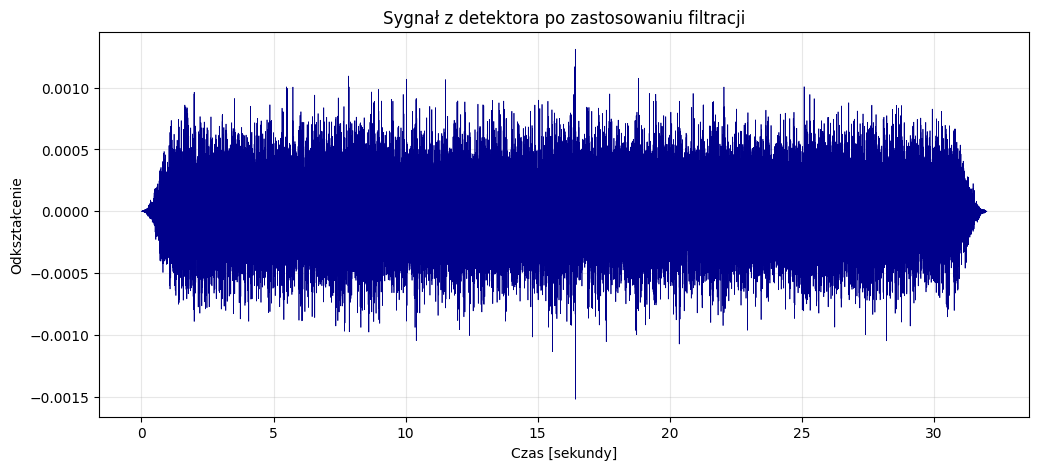

In [55]:
plt.figure(figsize=(12,5))
plt.plot(df['Czas'], df['Przefiltrowane'], color='darkblue', linewidth=0.5)
plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.xlabel("Czas [sekundy]")
plt.ylabel("Odkształcenie")
plt.grid(True, alpha=0.3)
plt.show()

In [56]:
DATA_2 = "L-L1_LOSC_4_V2-1126259446-32.txt.gz"

In [57]:
df_2 = pd.read_csv(DATA_2, compression='gzip', comment='#', names=['Odksztalcenie'])

In [58]:
df_2.head(5)

,Odksztalcenie
0,-1.042900e-18
1,-1.035863e-18
2,-9.893224e-19
3,-9.375604e-19
4,-9.417111e-19


In [59]:
df_2.index = df_2.index + 1
df_2.head(5)


,Odksztalcenie
1,-1.042900e-18
2,-1.035863e-18
3,-9.893224e-19
4,-9.375604e-19
5,-9.417111e-19


In [60]:
df_2.dtypes

Odksztalcenie    float64
dtype: object

In [61]:
df_2.duplicated().sum()

0

In [62]:
df_2.isnull().sum()

Odksztalcenie    0
dtype: int64

In [63]:
df_2.sample(5)

,Odksztalcenie
117986,-1.015228e-18
122597,-1.390509e-18
113956,-1.212173e-18
102794,-7.399370e-19
100721,-1.265079e-18


In [64]:
df_2.describe()

,Odksztalcenie
count,1.310720e+05
mean,-1.052233e-18
std,2.336114e-19
min,-1.869714e-18
25%,-1.200818e-18
50%,-1.053353e-18
75%,-9.020457e-19
max,-4.600351e-20


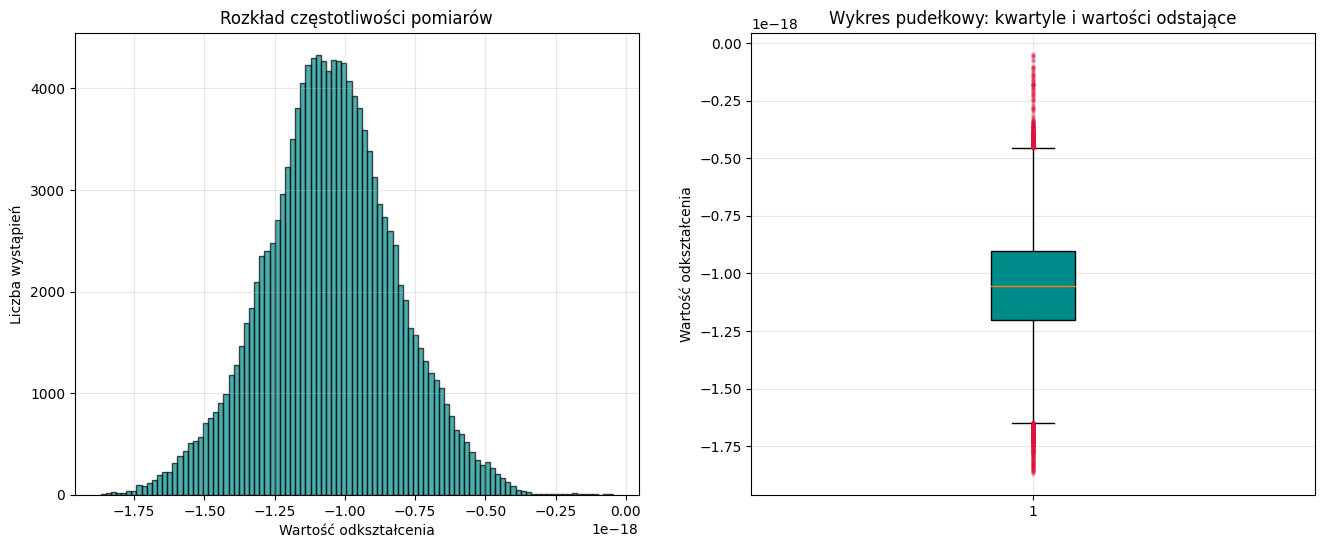

In [65]:
fig, (hist, box) = plt.subplots(1, 2, figsize=(16,6))

hist.hist(df_2['Odksztalcenie'], bins = 100, color = 'darkcyan', edgecolor='black', alpha=0.7)
hist.set_title('Rozkład częstotliwości pomiarów')
hist.set_xlabel("Wartość odkształcenia")
hist.set_ylabel("Liczba wystąpień")
hist.grid(True, alpha=0.3)

box.boxplot(df_2['Odksztalcenie'], patch_artist=True, 
            boxprops=dict(facecolor='darkcyan', edgecolor='black'),
            flierprops=dict(
                marker='o',
                markerfacecolor='crimson',
                markeredgecolor='none',
                markersize=3.0,
                alpha=0.2,
                linestyle='none'           )

            )
box.set_title("Wykres pudełkowy: kwartyle i wartości odstające")
box.set_ylabel("Wartość odkształcenia")
box.grid(True, alpha=0.3)

plt.show()

In [66]:
df_2.head(5)

,Odksztalcenie
1,-1.042900e-18
2,-1.035863e-18
3,-9.893224e-19
4,-9.375604e-19
5,-9.417111e-19


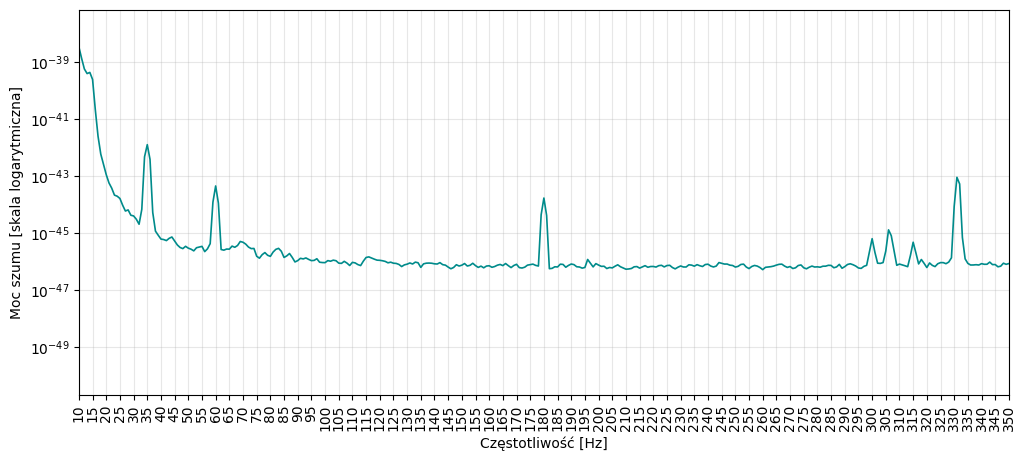

In [67]:
f, p = signal.welch(df_2['Odksztalcenie'].values, fs=4096.0, nperseg=4096)

plt.figure(figsize=(12,5))
plt.semilogy(f, p, color='darkcyan', linewidth=1.2, label = "Surowy sygnał")
plt.xlabel("Częstotliwość [Hz]")
plt.ylabel("Moc szumu [skala logarytmiczna]")
plt.xticks(np.arange(10,360,5), rotation=90)
plt.xlim(10,350)
plt.grid(True, alpha=0.3)
plt.show()

In [68]:
b_notch60, a_notch60 = signal.iirnotch(60.0, Q=30.0, fs=4096.0)
df_2["Odksztalcenie"] = signal.filtfilt(b_notch60, a_notch60, df_2['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(300.0, Q=30.0, fs=4096.0)
df_2['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df_2['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(35.0, Q=30.0, fs=4096.0)
df_2['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df_2['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(180.0, Q=30.0, fs=4096.0)
df_2['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df_2['Odksztalcenie'])

b_notch300, a_notch300 = signal.iirnotch(331.0, Q=30.0, fs=4096.0)
df_2['Odksztalcenie'] = signal.filtfilt(b_notch300, a_notch300, df_2['Odksztalcenie'])

In [69]:
df_2['Oczyszczone'] = signal.detrend(df_2['Odksztalcenie'])

In [70]:
sygnal_fft = fft.rfft(df_2['Oczyszczone'].values)

profil_szumu = np.abs(sygnal_fft)
profil_szumu_wygładzony = signal.medfilt(profil_szumu, kernel_size=501)

sygnal_fft_wybielony = sygnal_fft / (profil_szumu_wygładzony + 1e-25)

df_2['Oczyszczone'] = fft.irfft(sygnal_fft_wybielony, n=len(df_2))

In [71]:
tukey_window = signal.windows.tukey(len(df), alpha=0.1)
df_2['Oczyszczone_tukey'] = df_2["Oczyszczone"] * tukey_window

In [72]:
f_low = 35.0
f_high = 350.0

nyquist = 0.5 * 4096

low = f_low/nyquist
high = f_high/nyquist
b, a = signal.butter(4, [low, high], btype='band')
df_2["Przefiltrowane"] = signal.filtfilt(b, a, df_2["Oczyszczone_tukey"])

In [73]:
df_2['Czas'] = np.linspace(0,32,len(df_2))

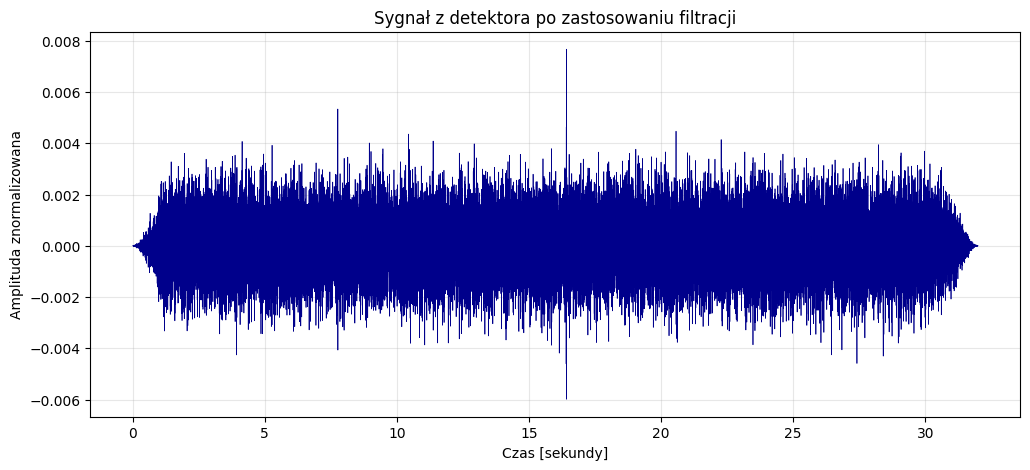

In [74]:
plt.figure(figsize=(12,5))

plt.plot(df_2['Czas'], df_2['Przefiltrowane'], color='darkblue', linewidth=0.5 )



plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.grid(True, alpha=0.3)
plt.xlabel("Czas [sekundy]")
plt.ylabel("Amplituda znormalizowana")

plt.show()

Around 16th second there is clearly visible anomaly. It appears both on Livingstone and Hanford plot.

In [75]:
df_ai = pd.DataFrame()

In [76]:
df_ai["Czas"] = df['Czas']
df_ai["Oczyszczone_Hanford"] = df['Przefiltrowane']
df_ai["Oczyszczone_Livingstone"] = df_2['Przefiltrowane']
df_ai["Etykieta"] = 0


In [77]:
df_ai.head(10)

,Czas,Oczyszczone_Hanford,Oczyszczone_Livingstone,Etykieta
1,0.000000,5.254300e-08,-5.485411e-08,0
2,0.000244,4.560397e-08,-4.687370e-08,0
3,0.000488,3.791330e-08,-3.059884e-08,0
4,0.000732,2.868130e-08,1.311158e-09,0
5,0.000977,1.754364e-08,5.293890e-08,0
6,0.001221,4.674287e-09,1.233521e-07,0
7,0.001465,-9.168571e-09,2.053582e-07,0
8,0.001709,-2.270227e-08,2.854269e-07,0
9,0.001953,-3.432225e-08,3.454917e-07,0
10,0.002197,-4.244671e-08,3.670045e-07,0


In [78]:
df_ai.isnull().sum()

Czas                       0
Oczyszczone_Hanford        0
Oczyszczone_Livingstone    0
Etykieta                   0
dtype: int64

In [79]:
df_ai.dtypes

Czas                       float64
Oczyszczone_Hanford        float64
Oczyszczone_Livingstone    float64
Etykieta                     int64
dtype: object

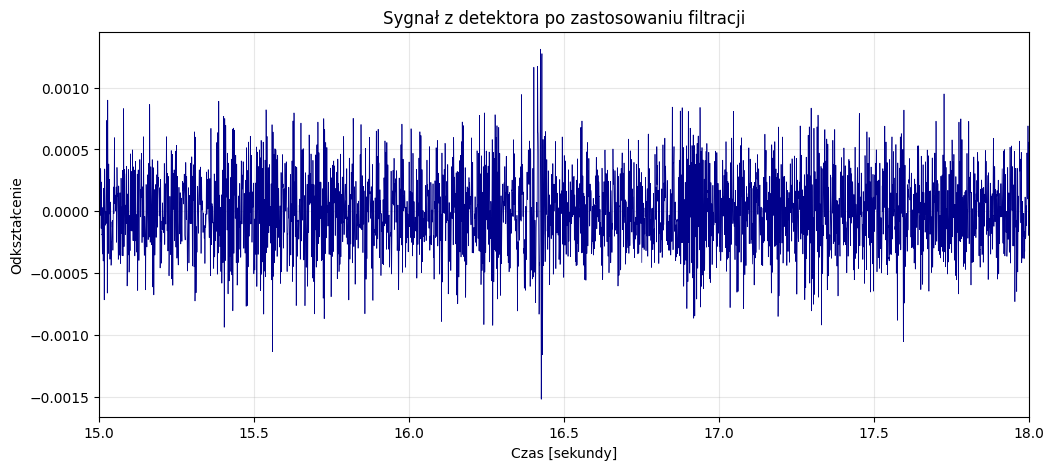

In [80]:
plt.figure(figsize=(12,5))
plt.plot(df['Czas'], df['Przefiltrowane'], color='darkblue', linewidth=0.5)
plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.xlabel("Czas [sekundy]")
plt.ylabel("Odkształcenie")
plt.grid(True, alpha=0.3)
plt.xlim(15.0, 18.0)
plt.show()

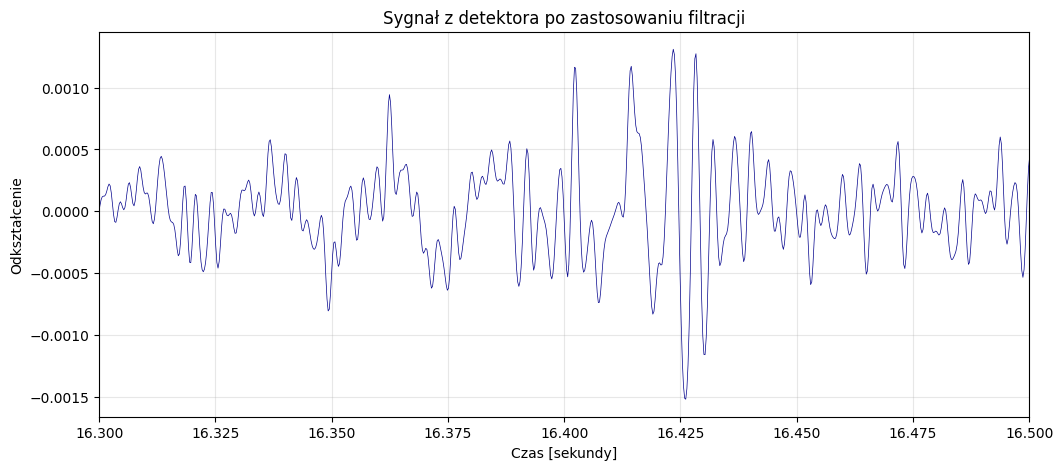

In [81]:
plt.figure(figsize=(12,5))
plt.plot(df['Czas'], df['Przefiltrowane'], color='darkblue', linewidth=0.5)
plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.xlabel("Czas [sekundy]")
plt.ylabel("Odkształcenie")
plt.grid(True, alpha=0.3)
plt.xlim(16.3, 16.5)
plt.show()

16.400 - 16.435

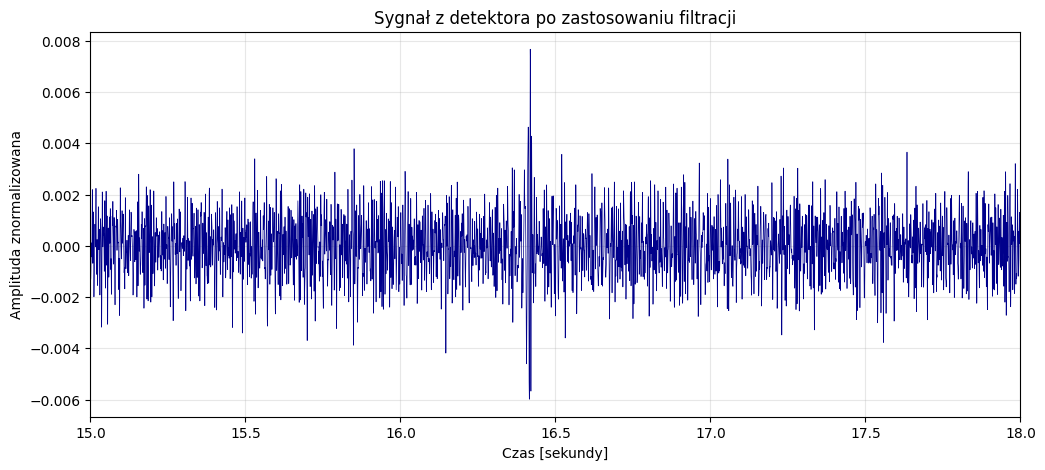

In [82]:
plt.figure(figsize=(12,5))
plt.plot(df_2['Czas'], df_2['Przefiltrowane'], color='darkblue', linewidth=0.5 )
plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.grid(True, alpha=0.3)
plt.xlabel("Czas [sekundy]")
plt.ylabel("Amplituda znormalizowana")
plt.xlim(15.0, 18.0)
plt.show()

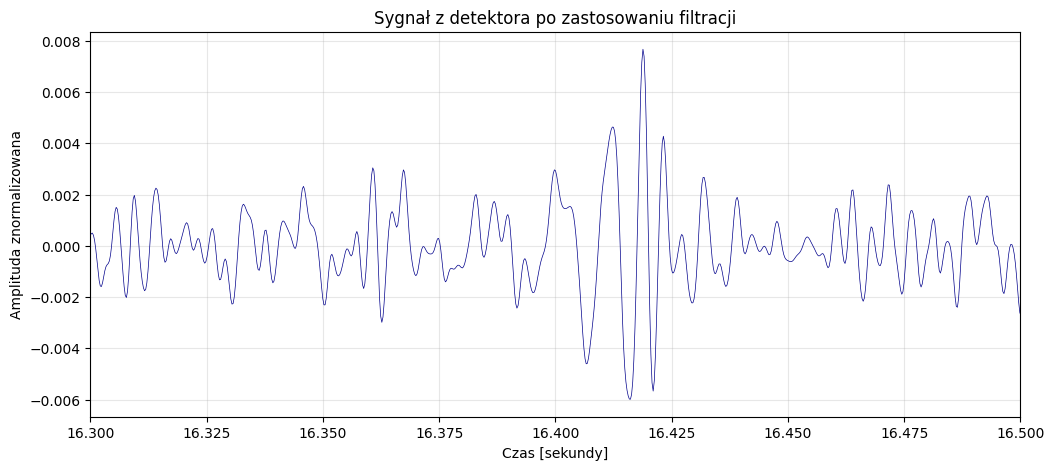

In [83]:
plt.figure(figsize=(12,5))
plt.plot(df_2['Czas'], df_2['Przefiltrowane'], color='darkblue', linewidth=0.5 )
plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.grid(True, alpha=0.3)
plt.xlabel("Czas [sekundy]")
plt.ylabel("Amplituda znormalizowana")
plt.xlim(16.3, 16.5)
plt.show()

16.400-16.435

In [84]:
df_ai.head(5)

,Czas,Oczyszczone_Hanford,Oczyszczone_Livingstone,Etykieta
1,0.000000,5.254300e-08,-5.485411e-08,0
2,0.000244,4.560397e-08,-4.687370e-08,0
3,0.000488,3.791330e-08,-3.059884e-08,0
4,0.000732,2.868130e-08,1.311158e-09,0
5,0.000977,1.754364e-08,5.293890e-08,0


In [85]:
start = 16.400
koniec = 16.435

In [86]:
przedział = ((df_ai['Czas']>=start) & (df_ai["Czas"]<=koniec))

In [87]:
df_ai.loc[przedział, 'Etykieta'] = 1

In [88]:
df_ai.loc[przedział, 'Etykieta']

67175    1
67176    1
67177    1
67178    1
67179    1
        ..
67314    1
67315    1
67316    1
67317    1
67318    1
Name: Etykieta, Length: 144, dtype: int64

In [89]:
df_ai.head(3)

,Czas,Oczyszczone_Hanford,Oczyszczone_Livingstone,Etykieta
1,0.000000,5.254300e-08,-5.485411e-08,0
2,0.000244,4.560397e-08,-4.687370e-08,0
3,0.000488,3.791330e-08,-3.059884e-08,0


In [90]:
df_ai["Etykieta"].value_counts()

Etykieta
0    130928
1       144
Name: count, dtype: int64

In [92]:
exp = setup(
    data=df_ai,
    session_id=42,
    normalize = True,
    
    ignore_features = ['Czas'],
    verbose=True,
    target="Etykieta"
)

,Description,Value
0,Session id,42
1,Target,Etykieta
2,Target type,Binary
3,Original data shape,"(131072, 4)"
4,Transformed data shape,"(131072, 3)"
5,Transformed train set shape,"(91750, 3)"
6,Transformed test set shape,"(39322, 3)"
7,Ignore features,1
8,Numeric features,2
9,Preprocess,True


In [94]:
best_model = compare_models(sort="F1")

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.9992,0.7382,0.3055,0.8881,0.4353,0.4351,0.5052,5.3360
nb,Naive Bayes,0.9991,0.8954,0.2864,0.7633,0.4031,0.4027,0.4557,0.0240
qda,Quadratic Discriminant Analysis,0.9991,0.8955,0.2864,0.7633,0.4031,0.4027,0.4557,0.0280
gbc,Gradient Boosting Classifier,0.9990,0.6281,0.2836,0.5661,0.3554,0.3550,0.3841,3.4560
et,Extra Trees Classifier,0.9990,0.7387,0.2464,0.6350,0.3504,0.3500,0.3918,0.7440
knn,K Neighbors Classifier,0.9991,0.7111,0.2264,0.8633,0.3488,0.3485,0.4321,0.2400
ada,Ada Boost Classifier,0.9990,0.8760,0.2173,0.6600,0.3150,0.3146,0.3678,0.8740
dt,Decision Tree Classifier,0.9986,0.6478,0.2964,0.3255,0.3031,0.3024,0.3062,0.2090
catboost,CatBoost Classifier,0.9988,0.8474,0.0791,0.2750,0.1188,0.1184,0.1438,11.4130
lr,Logistic Regression,0.9989,0.3489,0.0000,0.0000,0.0000,0.0000,0.0000,1.5310


In [96]:
model_rf = create_model('rf', verbose=False)
model_qda = create_model('qda', verbose=False)
model_knn = create_model('knn', verbose=False)

In [97]:
tuned_rf = tune_model(model_rf, optimize='F1')
tuned_qda = tune_model(model_qda, optimize='F1')
tuned_knn = tune_model(model_knn, optimize='F1')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9991,0.8673,0.3000,0.7500,0.4286,0.4282,0.4740
1,0.9990,0.9056,0.3000,0.6000,0.4000,0.3996,0.4238
2,0.9990,0.8733,0.1000,1.0000,0.1818,0.1817,0.3161
3,0.9993,0.8443,0.4000,1.0000,0.5714,0.5712,0.6322
4,0.9992,0.8775,0.3000,1.0000,0.4615,0.4613,0.5475
5,0.9992,0.9490,0.3000,1.0000,0.4615,0.4613,0.5475
6,0.9988,0.8487,0.2000,0.4000,0.2667,0.2661,0.2823
7,0.9991,0.9010,0.4000,0.6667,0.5000,0.4996,0.5160
8,0.9990,0.9218,0.2000,0.6667,0.3077,0.3073,0.3648


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9990,0.8920,0.2000,0.6667,0.3077,0.3073,0.3648
1,0.9991,0.8878,0.3000,0.7500,0.4286,0.4282,0.4740
2,0.9990,0.8079,0.1000,1.0000,0.1818,0.1817,0.3161
3,0.9992,0.8518,0.4000,0.8000,0.5333,0.5330,0.5654
4,0.9992,0.9038,0.4000,0.8000,0.5333,0.5330,0.5654
5,0.9992,0.9214,0.4000,0.8000,0.5333,0.5330,0.5654
6,0.9989,0.8803,0.1000,0.5000,0.1667,0.1664,0.2233
7,0.9992,0.9304,0.4000,0.8000,0.5333,0.5330,0.5654
8,0.9990,0.9433,0.2000,0.6667,0.3077,0.3073,0.3648


Fitting 10 folds for each of 10 candidates, totalling 100 fits


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9991,0.7983,0.2000,1.0000,0.3333,0.3331,0.4470
1,0.9992,0.6992,0.3000,1.0000,0.4615,0.4613,0.5475
2,0.9990,0.5989,0.1000,1.0000,0.1818,0.1817,0.3161
3,0.9990,0.6992,0.1000,1.0000,0.1818,0.1817,0.3161
4,0.9991,0.6992,0.3000,0.7500,0.4286,0.4282,0.4740
5,0.9990,0.7491,0.1000,1.0000,0.1818,0.1817,0.3161
6,0.9991,0.6992,0.2000,1.0000,0.3333,0.3331,0.4470
7,0.9991,0.7992,0.2000,1.0000,0.3333,0.3331,0.4470
8,0.9990,0.5987,0.2000,0.6667,0.3077,0.3073,0.3648


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


In [137]:
final_rf_model = finalize_model(tuned_rf)

In [138]:
save_model(final_rf_model, 'Best_Prototype_Model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Oczyszczone_Hanford',
                                              'Oczyszczone_Livingstone'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='mean'))),
                 ('categorical_imputer',
                  TransformerWrapper(exclude=None, inc...
                  RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                         class_weight=None, cr

## Conclusion:
### High risk of overfitting or data leakage.

## 2. Final version:

In [10]:
import pandas as pd
import numpy as np
from scipy.signal import welch, find_peaks, iirnotch, filtfilt, detrend
from scipy.fft import fft, ifft
import matplotlib.pyplot as plt
import os



In [11]:
gps_list = {

    "H-H1_GWOSC_4KHZ_R1-1268903496-32.txt.gz" : 1268903511.3,
    "H-H1_GWOSC_4KHZ_R1-1268431079-32.txt.gz" : 1268431094.1,
    "H-H1_GWOSC_4KHZ_R1-1267963136-32.txt.gz" : 1267963151.3,
    "H-H1_GWOSC_4KHZ_R1-1266645864-32.txt.gz" : 1266645879.3,
    "H-H1_GWOSC_4KHZ_R1-1266618157-32.txt.gz" : 1266618172.4,
    "H-H1_GWOSC_4KHZ_R1-1266238133-32.txt.gz" : 1266238148.1,
    "H-H1_GWOSC_4KHZ_R1-1253326729-32.txt.gz" : 1253326744.8,
    "H-H1_GWOSC_4KHZ_R1-1242442952-32.txt.gz" : 1242442967.4,
    "H-H1_GWOSC_4KHZ_R1-1126259447-32.txt.gz" : 1126259462.4,
    "H-H1_GWOSC_4KHZ_R1-1185389792-32.txt.gz" : 1185389807.3,
    "H-H1_GWOSC_4KHZ_R1-1239198191-32.txt.gz" : 1239198206.7,
    "H-H1_GWOSC_4KHZ_R1-1239917939-32.txt.gz" : 1239917954.2,
    "H-H1_GWOSC_4KHZ_R1-1240944847-32.txt.gz" : 1240944862.2,
    "H-H1_GWOSC_4KHZ_R1-1241852059-32.txt.gz" : 1241852074.8,
    "H-H1_GWOSC_4KHZ_R1-1242107464-32.txt.gz" : 1242107479.8,
    "H-H1_GWOSC_4KHZ_R1-1242459842-32.txt.gz" : 1242459857.4,
    "H-H1_GWOSC_4KHZ_R1-1246048389-32.txt.gz" : 1246048404.5,
    "H-H1_GWOSC_4KHZ_R1-1248242616-32.txt.gz" : 1248242631.9,
    "H-H1_GWOSC_4KHZ_R1-1248617379-32.txt.gz" : 1248617394.6,
    "H-H1_GWOSC_4KHZ_R1-1248834424-32.txt.gz" : 1248834439.8,
    "H-H1_GWOSC_4KHZ_R1-1261020940-32.txt.gz" : 1261020955.1,
    
    


    

    

}

    

In [12]:

def automatic_notch(df, fs=4096):
    

    f_h, p_h = welch(df['Oczyszczone_Hanford'].values, fs=fs, nperseg=fs*2)
    prog_h = np.mean(p_h) * 5
    piki_h = find_peaks(p_h, prominence=prog_h, distance=10)[0]

    frequencies_h = []
    for freq in f_h[piki_h]:
        if 10<= freq <= 350:
            frequencies_h.append(freq)
            
    for freq in frequencies_h:
        b, a = iirnotch(freq, Q=30.0, fs=fs)
        df['Oczyszczone_Hanford'] = filtfilt(b, a, df['Oczyszczone_Hanford'].values)

    f_l, p_l = welch(df['Oczyszczone_Livingstone'].values, fs=fs, nperseg=fs*2)
    prog_l = np.max(p_l)*0.005
    piki_l = find_peaks(p_l, prominence=prog_l, distance=10)[0]

    frequencies_l = []
    for freq in f_l[piki_l]:
        if 10<= freq <= 350:
            frequencies_l.append(freq)
    
    for freq in frequencies_l:
        b, a = iirnotch(freq, Q=30.0, fs=fs)
        df['Oczyszczone_Livingstone'] = filtfilt(b, a, df['Oczyszczone_Livingstone'].values)

    return df

In [13]:
def detrending(df):
    df['Oczyszczone_Hanford'] = df['Surowe_Hanford']
    df['Oczyszczone_Livingstone'] = df['Surowe_Livingstone']

    df["Oczyszczone_Hanford"] = detrend(df["Oczyszczone_Hanford"])
    df["Oczyszczone_Livingstone"] = detrend(df["Oczyszczone_Hanford"])

    return df

In [70]:
def whitening(df, fs=4096):

    from scipy import fft

    sygnal_fft = fft.rfft(df['Oczyszczone_Hanford'].values)


    profil_szumu = np.abs(sygnal_fft)
    profil_szumu_wygładzony = signal.medfilt(profil_szumu, kernel_size=501)

    sygnal_fft_wybielony = sygnal_fft / (profil_szumu_wygładzony + 1e-25)

    df['Oczyszczone_Hanford'] = fft.irfft(sygnal_fft_wybielony, n=len(df))

    sygnal_fft = fft.rfft(df['Oczyszczone_Livingstone'].values)
    
    
    profil_szumu = np.abs(sygnal_fft)
    profil_szumu_wygładzony = signal.medfilt(profil_szumu, kernel_size=501)
    
    sygnal_fft_wybielony = sygnal_fft / (profil_szumu_wygładzony + 1e-25)
    
    df['Oczyszczone_Livingstone'] = fft.irfft(sygnal_fft_wybielony, n=len(df))

    return df



In [52]:
def Tukey_window(df):
    tukey_window = signal.windows.tukey(len(df), alpha=0.1)
    df['Oczyszczone_Hanford'] = df["Oczyszczone_Hanford"] * tukey_window
    df["Oczyszczone_Livingstone"] = df["Oczyszczone_Livingstone"] * tukey_window

    return df
    

In [16]:
def butterworth(df, fs=4096, f_low=35.0, f_high=350.0):

    nyquist = 0.5 * fs

    low = f_low/nyquist
    high = f_high/nyquist
    b, a = signal.butter(4, [low, high], btype='band')
    df["Oczyszczone_Hanford"] = signal.filtfilt(b, a, df["Oczyszczone_Hanford"])
    df["Oczyszczone_Livingstone"] = signal.filtfilt(b, a, df["Oczyszczone_Livingstone"])

    return df

In [71]:
def cleaning(df, fs=4096, f_low=35.0, f_high=350.0):
    
    df = detrending(df)
    df = Tukey_window(df)
    df = whitening(df, fs=fs)
    df = butterworth(df, fs=fs, f_low=f_low, f_high=f_high)
    df = automatic_notch(df, fs=fs)
   

    return df

In [58]:
def read_raw(path_h_r, path_l_r, fs=4096):
    df_h_r = pd.read_csv(path_h_r, compression='gzip', comment='#', names=['Surowe_Hanford'])
    df_l_r = pd.read_csv(path_l_r, compression='gzip', comment='#', names=["Surowe_Livingstone"])

    time = np.linspace(0,32,len(df_h_r))

    df_raw = pd.DataFrame({
        'Czas' : time,
        'Surowe_Hanford' : df_h_r['Surowe_Hanford'],
        'Surowe_Livingstone' : df_l_r['Surowe_Livingstone'],
    })

    return df_raw

Test:

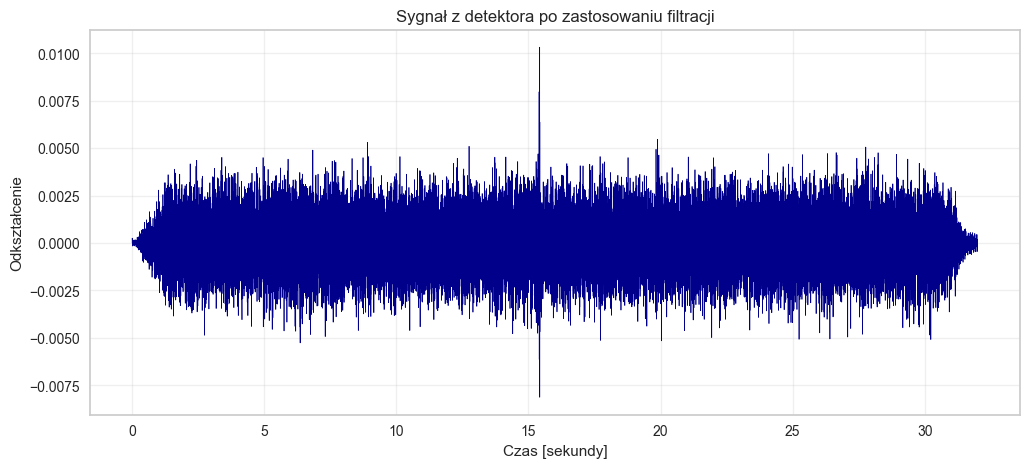

In [107]:
folder_h = 'surowe_hanford_test'
folder_l = 'surowe_livingstone_test'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    

plt.figure(figsize=(12,5))
plt.plot(x_2['Czas'], x_2['Oczyszczone_Hanford'], color='darkblue', linewidth=0.5)
plt.title("Sygnał z detektora po zastosowaniu filtracji")
plt.xlabel("Czas [sekundy]")
plt.ylabel("Odkształcenie")
plt.grid(True, alpha=0.3)
plt.show()


Instead of one big model it is better to create a few more specialised ones, each in different category.

Categories are based on total mass of black hole pairs and their mass ratio.

Black hole categories:
1. 100-200+ MS, 0.6-1.0
2. 60-100 MS, 0.5-1.0
3. 35-60 MS, 0.4-1.0 
4. 50-75 MS, 0.2-0.5
5. 10-35 MS, 0.3-1.0

Below are 5 different data preparation loops for model training. This notebook focuses on the model specialized for Category 2; the implementation for the remaining categories is identical.


### Due to the emphasis on Category 2, its pipeline code is distinct and significantly more developed than the others.


In [112]:
folder_h = 'surowe_hanford_1'
folder_l = 'surowe_livingstone_1'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    x_2['Target'] = 0
    gps_point = gps_list[file_h]
    start_point = float(re.search(r'\b\d{10}\b', file_h).group())
    main_point = gps_point - start_point
   

    x_2.loc[(x_2['Czas'] >= main_point - 0.010) & (x_2['Czas'] <= main_point + 0.005), 'Target'] = 1

    final_list.append(x_2)

    


In [113]:
df_AI_1 = pd.concat(final_list, ignore_index=True)

### Category 2:

In [81]:
folder_h = 'surowe_hanford_2'
folder_l = 'surowe_livingstone_2'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    x_2['Target'] = 0
    gps_point = gps_list[file_h]
    start_point = float(re.search(r'\b\d{10}\b', file_h).group())
    main_point = gps_point - start_point
    x_2.loc[(x_2['Czas'] >= main_point - 0.025) & (x_2['Czas'] <= main_point + 0.010), 'Target'] = 1

    x_2= x_2[(x_2['Czas'] >= 3.0) & (x_2['Czas'] <= 29.0)]



    for i in range(1, 11):
        x_2[f'H_lag_{i}'] = x_2['Oczyszczone_Hanford'].shift(i)
        x_2[f'L_lag_{i}'] = x_2['Oczyszczone_Livingstone'].shift(i)
        x_2[f'H_lead_{i}'] = x_2['Oczyszczone_Hanford'].shift(-i)
        x_2[f'L_lead_{i}'] = x_2['Oczyszczone_Livingstone'].shift(-i)

    windows_sizes = [8, 16, 32, 64, 128, 256]

    x_2['HL_product'] = x_2['Oczyszczone_Hanford'] * x_2['Oczyszczone_Livingstone']

    bg_std_h = x_2['Oczyszczone_Hanford'].rolling(window=1024, min_periods=1, center=True).std() + 1e-30
    bg_std_l = x_2['Oczyszczone_Livingstone'].rolling(window=1024, min_periods=1, center=True).std() + 1e-30

    for window_size in windows_sizes:
        
        x_2[f'H_roll_std_{window_size}'] = x_2['Oczyszczone_Hanford'].rolling(window=window_size, min_periods=1, center=True).std()
        x_2[f'L_roll_std_{window_size}'] = x_2['Oczyszczone_Livingstone'].rolling(window=window_size, min_periods=1, center=True).std()
        
        
        x_2[f'H_roll_mean_{window_size}'] = x_2['Oczyszczone_Hanford'].rolling(window=window_size, min_periods=1, center=True).mean()
        x_2[f'L_roll_mean_{window_size}'] = x_2['Oczyszczone_Livingstone'].rolling(window=window_size, min_periods=1, center=True).mean()
        
        
        x_2[f'H_roll_max_{window_size}'] = x_2['Oczyszczone_Hanford'].abs().rolling(window=window_size, min_periods=1, center=True).max()
        x_2[f'L_roll_max_{window_size}'] = x_2['Oczyszczone_Livingstone'].abs().rolling(window=window_size, min_periods=1, center=True).max()

        x_2[f'H_energy_{window_size}'] = (x_2['Oczyszczone_Hanford'] ** 2).rolling(window=window_size, min_periods=1, center=True).sum()
        x_2[f'L_energy_{window_size}'] = (x_2['Oczyszczone_Livingstone'] ** 2).rolling(window=window_size, min_periods=1, center=True).sum()

        x_2[f'HL_cross_energy_{window_size}'] = x_2['HL_product'].rolling(window=window_size, min_periods=1, center=True).mean()

        x_2[f'H_local_SNR_{window_size}'] = x_2[f'H_roll_max_{window_size}'] / bg_std_h
        x_2[f'L_local_SNR_{window_size}'] = x_2[f'L_roll_max_{window_size}'] / bg_std_l



    x_2 = x_2.dropna()


    final_list.append(x_2)

    


In [82]:
df_AI_2 = pd.concat(final_list, ignore_index=True)

In [116]:
folder_h = 'surowe_hanford_3'
folder_l = 'surowe_livingstone_3'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    x_2['Target'] = 0
    gps_point = gps_list[file_h]
    start_point = float(re.search(r'\b\d{10}\b', file_h).group())
    main_point = gps_point - start_point
    x_2.loc[(x_2['Czas'] >= main_point - 0.120) & (x_2['Czas'] <= main_point + 0.030), 'Target'] = 1

    final_list.append(x_2)

    


In [117]:
df_AI_3 = pd.concat(final_list, ignore_index=True)

In [118]:
folder_h = 'surowe_hanford_4'
folder_l = 'surowe_livingstone_4'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    x_2['Target'] = 0
    gps_point = gps_list[file_h]
    start_point = float(re.search(r'\b\d{10}\b', file_h).group())
    main_point = gps_point - start_point
    x_2.loc[(x_2['Czas'] >= main_point - 0.080) & (x_2['Czas'] <= main_point + 0.020), 'Target'] = 1

    final_list.append(x_2)

    


In [119]:
df_AI_4 = pd.concat(final_list, ignore_index=True)

In [120]:
folder_h = 'surowe_hanford_5'
folder_l = 'surowe_livingstone_5'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    x_2['Target'] = 0
    gps_point = gps_list[file_h]
    start_point = float(re.search(r'\b\d{10}\b', file_h).group())
    main_point = gps_point - start_point
    x_2.loc[(x_2['Czas'] >= main_point - 4.000) & (x_2['Czas'] <= main_point + 0.500), 'Target'] = 1

    final_list.append(x_2)

    


In [121]:
df_AI_5 = pd.concat(final_list, ignore_index=True)

### Data prepared for testing models:

In [85]:
folder_h = 'surowe_hanford_test'
folder_l = 'surowe_livingstone_test'

final_list = []

files_h = []

for name in os.listdir(folder_h):
    files_h.append(name)

for file_h in files_h:
    path_h = os.path.join(folder_h, file_h)

    file_l = file_h.replace('H-H1_', 'L-L1_')
    path_l = os.path.join(folder_l, file_l)

    x_1 = read_raw(path_h, path_l)
    x_2 = cleaning(x_1)

    x_2['Target'] = 0
    gps_point = gps_list[file_h]
    start_point = float(re.search(r'\b\d{10}\b', file_h).group())
    main_point = gps_point - start_point
    x_2.loc[(x_2['Czas'] >= main_point - 0.025) & (x_2['Czas'] <= main_point + 0.010), 'Target'] = 1

    x_2= x_2[(x_2['Czas'] >= 3.0) & (x_2['Czas'] <= 29.0)]



    for i in range(1, 11):
        x_2[f'H_lag_{i}'] = x_2['Oczyszczone_Hanford'].shift(i)
        x_2[f'L_lag_{i}'] = x_2['Oczyszczone_Livingstone'].shift(i)
        x_2[f'H_lead_{i}'] = x_2['Oczyszczone_Hanford'].shift(-i)
        x_2[f'L_lead_{i}'] = x_2['Oczyszczone_Livingstone'].shift(-i)

    windows_sizes = [8, 16, 32, 64, 128, 256]
    
    x_2['HL_product'] = x_2['Oczyszczone_Hanford'] * x_2['Oczyszczone_Livingstone']
    
    bg_std_h = x_2['Oczyszczone_Hanford'].rolling(window=1024, min_periods=1, center=True).std() + 1e-30
    bg_std_l = x_2['Oczyszczone_Livingstone'].rolling(window=1024, min_periods=1, center=True).std() + 1e-30

    for window_size in windows_sizes:
        
        x_2[f'H_roll_std_{window_size}'] = x_2['Oczyszczone_Hanford'].rolling(window=window_size, min_periods=1, center=True).std()
        x_2[f'L_roll_std_{window_size}'] = x_2['Oczyszczone_Livingstone'].rolling(window=window_size, min_periods=1, center=True).std()
        
        
        x_2[f'H_roll_mean_{window_size}'] = x_2['Oczyszczone_Hanford'].rolling(window=window_size, min_periods=1, center=True).mean()
        x_2[f'L_roll_mean_{window_size}'] = x_2['Oczyszczone_Livingstone'].rolling(window=window_size, min_periods=1, center=True).mean()
        
        
        x_2[f'H_roll_max_{window_size}'] = x_2['Oczyszczone_Hanford'].abs().rolling(window=window_size, min_periods=1, center=True).max()
        x_2[f'L_roll_max_{window_size}'] = x_2['Oczyszczone_Livingstone'].abs().rolling(window=window_size, min_periods=1, center=True).max()

        x_2[f'H_energy_{window_size}'] = (x_2['Oczyszczone_Hanford'] ** 2).rolling(window=window_size, min_periods=1, center=True).sum()
        x_2[f'L_energy_{window_size}'] = (x_2['Oczyszczone_Livingstone'] ** 2).rolling(window=window_size, min_periods=1, center=True).sum()
        
        x_2[f'HL_cross_energy_{window_size}'] = x_2['HL_product'].rolling(window=window_size, min_periods=1, center=True).mean()
        
        x_2[f'H_local_SNR_{window_size}'] = x_2[f'H_roll_max_{window_size}'] / bg_std_h
        x_2[f'L_local_SNR_{window_size}'] = x_2[f'L_roll_max_{window_size}'] / bg_std_l
    

    x_2 = x_2.dropna()


    final_list.append(x_2)

In [86]:
df_AI_test = pd.concat(final_list, ignore_index=True)

### A failed attempt at creating one large model trained on every category:

In [122]:
list_AI = [df_AI_1, df_AI_2, df_AI_3, df_AI_4, df_AI_5]


In [123]:
df_AI_FINAL = pd.concat(list_AI, ignore_index=True)

In [126]:
df_AI_FINAL.index = df_AI_FINAL.index + 1

In [127]:
df_AI_FINAL.head(5)

,Czas,Surowe_Hanford,Surowe_Livingstone,Oczyszczone_Hanford,Oczyszczone_Livingstone,Target
1,0.000000,2.815359e-21,1.373082e-20,-0.000055,0.000003,0
2,0.000244,-1.164952e-21,1.381368e-20,-0.000107,-0.000029,0
3,0.000488,1.021701e-20,1.376701e-20,-0.000152,-0.000060,0
4,0.000732,1.684095e-20,1.126553e-20,-0.000186,-0.000089,0
5,0.000977,1.061565e-20,1.011002e-20,-0.000206,-0.000112,0


In [128]:
df_AI_FINAL.sample(5)

,Czas,Surowe_Hanford,Surowe_Livingstone,Oczyszczone_Hanford,Oczyszczone_Livingstone,Target
241966,27.073693,-1.132252e-19,-1.607998e-19,-0.000093,-0.000086,0
973019,13.553326,-2.640350e-20,9.343938e-20,0.002430,0.001250,1
653427,31.528073,-1.355000e-20,1.187281e-19,-0.000020,-0.000087,0
224202,22.736746,3.713706e-19,-1.105854e-18,0.000044,0.000004,0
758656,25.218698,-4.799681e-21,-3.315671e-19,0.001980,0.000960,0


In [129]:
df_AI_FINAL.dtypes

Czas                       float64
Surowe_Hanford             float64
Surowe_Livingstone         float64
Oczyszczone_Hanford        float64
Oczyszczone_Livingstone    float64
Target                       int64
dtype: object

In [130]:
df_AI_FINAL.isnull().sum()

Czas                       0
Surowe_Hanford             0
Surowe_Livingstone         0
Oczyszczone_Hanford        0
Oczyszczone_Livingstone    0
Target                     0
dtype: int64

In [132]:
df_AI_FINAL.tail(3)

,Czas,Surowe_Hanford,Surowe_Livingstone,Oczyszczone_Hanford,Oczyszczone_Livingstone,Target
1048574,31.999512,-7.250384e-21,2.971973e-19,2.986926e-05,-0.000007,0
1048575,31.999756,2.924498e-21,2.879340e-19,1.646125e-05,-0.000019,0
1048576,32.000000,1.093572e-20,2.820253e-19,3.031019e-07,-0.000031,0


In [134]:
Exp = setup(
    data=df_AI_FINAL,
    session_id=42,
    normalize = True,
    
    ignore_features = ['Czas', 'Surowe_Hanford', 'Surowe_Livingstone'],
    verbose=True,
    target="Target"
)

,Description,Value
0,Session id,42
1,Target,Target
2,Target type,Binary
3,Original data shape,"(1048576, 6)"
4,Transformed data shape,"(1048576, 3)"
5,Transformed train set shape,"(734003, 3)"
6,Transformed test set shape,"(314573, 3)"
7,Ignore features,3
8,Numeric features,2
9,Preprocess,True


In [135]:
Best_model = compare_models(sort="F1")

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
dt,Decision Tree Classifier,0.9613,0.5039,0.0279,0.0271,0.0275,0.0077,0.0077,3.0590
nb,Naive Bayes,0.9774,0.6551,0.0136,0.0765,0.0231,0.0173,0.0243,0.1550
qda,Quadratic Discriminant Analysis,0.9790,0.6653,0.0058,0.0714,0.0108,0.0078,0.0149,0.1650
et,Extra Trees Classifier,0.9788,0.5557,0.0039,0.0428,0.0071,0.0039,0.0071,19.0620
knn,K Neighbors Classifier,0.9802,0.5238,0.0010,0.0739,0.0021,0.0015,0.0066,1.9520
rf,Random Forest Classifier,0.9802,0.5648,0.0006,0.0387,0.0011,0.0006,0.0024,85.6580
gbc,Gradient Boosting Classifier,0.9803,0.6668,0.0001,0.0146,0.0003,0.0000,-0.0001,39.2310
lr,Logistic Regression,0.9804,0.5005,0.0000,0.0000,0.0000,0.0000,0.0000,1.8440
svm,SVM - Linear Kernel,0.9804,0.4998,0.0000,0.0000,0.0000,0.0000,0.0000,0.3160
ridge,Ridge Classifier,0.9804,0.5004,0.0000,0.0000,0.0000,0.0000,0.0000,0.1490


### Category 2 model development:

In [66]:
xperiment = setup(
    data=df_AI_2,
    session_id=42,
    normalize = False,
    
    ignore_features = ['Czas', 'Surowe_Hanford', 'Surowe_Livingstone'],
    verbose=True,
    target="Target"
)

,Description,Value
0,Session id,42
1,Target,Target
2,Target type,Binary
3,Original data shape,"(319428, 64)"
4,Transformed data shape,"(319428, 61)"
5,Transformed train set shape,"(223599, 61)"
6,Transformed test set shape,"(95829, 61)"
7,Ignore features,3
8,Numeric features,60
9,Preprocess,True


In [57]:
dt_model = create_model('dt')


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9995,0.9831,0.9667,0.7436,0.8406,0.8403,0.8476
1,0.9996,0.8999,0.8000,0.8889,0.8421,0.8419,0.8431
2,0.9993,0.8831,0.7667,0.7188,0.7419,0.7416,0.7420
3,0.9996,0.9332,0.8667,0.8667,0.8667,0.8665,0.8665
4,0.9996,0.8999,0.8000,0.8571,0.8276,0.8274,0.8279
5,0.9996,0.9499,0.9000,0.8438,0.8710,0.8708,0.8712
6,0.9994,0.8998,0.8000,0.7500,0.7742,0.7739,0.7743
7,0.9995,0.9031,0.8065,0.8065,0.8065,0.8062,0.8062
8,0.9993,0.8547,0.7097,0.7857,0.7458,0.7454,0.7464


High risk of overfitting.

In [63]:
test_dt = predict_model(dt_model, data = df_AI_test)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Decision Tree Classifier,0.9986,0.5000,0.0000,0.0000,0.0000,-0.0000,-0.0002


Test confirms previous speculation.

In [64]:
rf_model = create_model('rf')


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9993,1.0000,0.4667,1.0000,0.6364,0.6361,0.6829
1,0.9991,0.9998,0.3000,1.0000,0.4615,0.4612,0.5475
2,0.9991,0.9999,0.3333,1.0000,0.5000,0.4997,0.5771
3,0.9991,0.9823,0.3333,1.0000,0.5000,0.4997,0.5771
4,0.9991,0.9984,0.3000,1.0000,0.4615,0.4612,0.5475
5,0.9990,0.9999,0.2667,1.0000,0.4211,0.4207,0.5161
6,0.9991,0.9999,0.3333,1.0000,0.5000,0.4997,0.5771
7,0.9991,0.9826,0.3226,1.0000,0.4878,0.4875,0.5677
8,0.9991,0.9999,0.3226,1.0000,0.4878,0.4875,0.5677


In [65]:
test_rf = predict_model(rf_model, data = df_AI_test)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9986,0.6271,0.0000,0.0000,0.0000,0.0000,0.0000


Probably same problem as previously.

In [71]:
rf_model_better = create_model(
    'rf',
    class_weight = {0 : 1, 1: 500},
    max_depth = 10,
    n_estimators = 150,


)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9882,0.9862,0.7000,0.0761,0.1373,0.1352,0.2283
1,0.9938,0.9895,0.7333,0.1447,0.2418,0.2401,0.3241
2,0.9938,0.9882,0.8000,0.1529,0.2567,0.2550,0.3481
3,0.9956,0.9829,0.7333,0.1947,0.3077,0.3062,0.3765
4,0.9943,0.9842,0.6667,0.1449,0.2381,0.2364,0.3091
5,0.9915,0.9886,0.7333,0.1073,0.1872,0.1853,0.2785
6,0.9963,0.9910,0.7000,0.2234,0.3387,0.3374,0.3942
7,0.9974,0.9913,0.6129,0.2879,0.3918,0.3906,0.4189
8,0.9954,0.9839,0.7419,0.1949,0.3087,0.3072,0.3788


In [69]:
test_rf_better = predict_model(rf_model_better, data = df_AI_test)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9986,0.6484,0.0000,0.0000,0.0000,0.0000,0.0000


In [80]:
test_theshold = predict_model(rf_model_better, data=df_AI_test, probability_threshold=0.30)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9983,0.7711,0.0833,0.2069,0.1188,0.1181,0.1306


Finally result over 0.0, useless model but quite improvement.

In [87]:
ex = setup(
    data=df_AI_2,
    session_id=42,
    normalize = False,
    
    ignore_features = ['Czas', 'Surowe_Hanford', 'Surowe_Livingstone', 'Oczyszczone_Hanford', 'Oczyszczone_Livingstone'],
    verbose=True,
    target="Target",
    data_split_shuffle=False,
    data_split_stratify=False,
)

,Description,Value
0,Session id,42
1,Target,Target
2,Target type,Binary
3,Original data shape,"(319428, 113)"
4,Transformed data shape,"(319428, 108)"
5,Transformed train set shape,"(223599, 108)"
6,Transformed test set shape,"(95829, 108)"
7,Ignore features,5
8,Numeric features,107
9,Preprocess,True


In [88]:
randomf_model = create_model(
    'rf',
    class_weight = 'balanced_subsample',
    max_depth = 10,
    n_estimators = 150,
    random_state = 42
)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9994,0.9999,0.5000,1.0000,0.6667,0.6664,0.7069
1,0.9990,0.9959,0.2143,1.0000,0.3529,0.3527,0.4627
2,0.9990,0.9995,0.6552,0.5938,0.6230,0.6224,0.6232
3,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,0.9993,1.0000,0.4828,1.0000,0.6512,0.6509,0.6946
5,0.9992,0.9996,0.3448,1.0000,0.5128,0.5125,0.5870
6,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,0.9997,1.0000,1.0000,0.8286,0.9062,0.9061,0.9101
8,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [89]:
Test = predict_model(randomf_model, data=df_AI_test, probability_threshold=0.05)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9986,0.6663,0.0347,0.3333,0.0629,0.0627,0.1072


### Pipeline Evolution and Overfitting Analysis

Note on the development process:
The data preparation pipeline was iteratively modified during training. 
* **Initial models:** The early results were heavily overfitted (the models were essentially "cheating" due to high correlation within the training split).
* **Final iteration:** The pipeline was adjusted to eliminate this bias, resulting in honest and more reliable metrics during validation.

However, despite these pipeline corrections, the final model still performs poorly on completely new, unseen data files. This highlights the massive challenge of generalizing models against the highly dynamic and time-varying background noise of the LIGO detectors.